# Ba câu hỏi thực tế về nhận dạng hoạt động bằng điện thoại

**Mục tiêu:** (1) người mới, (2) lỗi ngồi–đứng, (3) vai trò của cảm biến.

Notebook trình bày trực tiếp mã dữ liệu, mô hình, `model.fit()`, phân tích và câu trả lời dùng khi thuyết trình. Không cần gọi CLI hoặc import `har_project`.

**Phạm vi bằng chứng:** người mới/lỗi dùng dự đoán test đã lưu của protocol 1.0. Nghiên cứu cảm biến được thiết kế sau khi đã xem test, chỉ dùng official train và validation theo người. Không có test độc lập mới; không gọi điểm validation là kết quả triển khai thực tế.

## Cách chạy

Chọn kernel `.venv` của dự án. Mặc định `RUN_MODE="inspect"`: đọc, xác minh, vẽ lại trong notebook; không huấn luyện hoặc ghi vào bộ kết quả. `smoke`: 1 cấu hình, 1 seed, 1 epoch; `train`: 5 cấu hình × 3 seed. Chọn `RUN_NAME` mới cho mỗi đợt, **Save → Restart Kernel → Run All**. Không ghi đè đợt đã tồn tại. Snapshot lưu mã trên đĩa, cấu hình runtime lưu riêng.

Các checkpoint là hiện vật cục bộ, không được Git theo dõi; cần chuyển đủ hiện vật để xác minh toàn bộ manifest trên máy khác.

Thiết kế chi tiết: [practical-questions.md](../docs/research/practical-questions.md).

In [1]:
from pathlib import Path
import os, sys, json, time, hashlib, platform, importlib.metadata
from datetime import datetime, timezone

ROOT = Path.cwd().resolve()
if not (ROOT / "Dataset").is_dir() and (ROOT.parent / "Dataset").is_dir():
    ROOT = ROOT.parent
DATA_DIR = ROOT / "Dataset" / "UCI HAR Dataset"
SOURCE_RESULTS = ROOT / "results"
OUTPUT_BASE = ROOT / "practical_results"
RUN_MODE = "inspect"  # inspect | smoke | train
RUN_NAME = "sensor_study_v1"
STUDY_ROOT = OUTPUT_BASE / RUN_NAME
SEEDS = [42, 123, 2026]
VALIDATION_SUBJECTS = [5, 11, 19, 26]
LEARNING_RATE, BATCH_SIZE, MAX_EPOCHS, PATIENCE, DROPOUT = .001, 64, 50, 8, .3
if RUN_MODE not in {"inspect", "smoke", "train"}:
    raise ValueError("RUN_MODE không hợp lệ")
os.environ["MPLCONFIGDIR"] = str(ROOT / ".cache" / "matplotlib")
os.environ["TF_ENABLE_ONEDNN_OPTS"] = "0"
os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "2")
print("Mode:", RUN_MODE, "Output:", STUDY_ROOT)

Mode: inspect Output: E:\PPNCKH\SGU26_PPNCKH_Group\practical_results\sensor_study_v1


In [2]:
import numpy as np
import pandas as pd
import tensorflow as tf
import matplotlib
matplotlib.use("module://matplotlib_inline.backend_inline")
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix

try:
    tf.config.threading.set_intra_op_parallelism_threads(4)
    tf.config.threading.set_inter_op_parallelism_threads(2)
except RuntimeError:
    print("TensorFlow đã khởi tạo; giữ cấu hình thread hiện có. Restart kernel nếu cần đổi.")
tf.config.experimental.enable_op_determinism()
print("Python:", sys.version.split()[0])
print("TensorFlow:", tf.__version__)
print("Devices:", tf.config.list_physical_devices())

Python: 3.12.13
TensorFlow: 2.21.0


Devices: [PhysicalDevice(name='/physical_device:CPU:0', device_type='CPU')]


In [3]:
ACTIVITIES = ["WALKING", "WALKING_UPSTAIRS", "WALKING_DOWNSTAIRS", "SITTING", "STANDING", "LAYING"]
GROUPS = {
    "total_acc": [6, 7, 8],
    "gyro": [3, 4, 5],
    "total_acc_gyro": [6, 7, 8, 3, 4, 5],
    "body_acc_gyro": [0, 1, 2, 3, 4, 5],
    "all_9": list(range(9)),
}

def prepare_channels(fit_raw, validation_raw, group):
    if group not in GROUPS:
        raise ValueError("Nhóm kênh không hợp lệ")
    a, b = fit_raw[:, :, GROUPS[group]], validation_raw[:, :, GROUPS[group]]
    if a.ndim != 3 or len(a) == 0 or not np.isfinite(a).all() or not np.isfinite(b).all():
        raise ValueError("Dữ liệu không hữu hạn hoặc rỗng")
    mean = a.mean(axis=(0, 1), keepdims=True, dtype=np.float64)
    std = np.maximum(a.std(axis=(0, 1), keepdims=True, dtype=np.float64), 1e-8)
    return ((a-mean)/std).astype(np.float32), ((b-mean)/std).astype(np.float32), mean, std

def calculate_metrics(truth, predictions):
    cm = confusion_matrix(truth, predictions, labels=list(range(6)))
    report = classification_report(truth, predictions, labels=list(range(6)), target_names=ACTIVITIES,
                                   output_dict=True, zero_division=0)
    return {
        "accuracy": float(accuracy_score(truth, predictions)),
        "macro_f1": float(f1_score(truth, predictions, labels=list(range(6)), average="macro", zero_division=0)),
        "sit_stand_errors": int(cm[3, 4] + cm[4, 3]),
        "sitting_to_standing": int(cm[3, 4]), "standing_to_sitting": int(cm[4, 3]),
        "total_errors": int(np.sum(cm) - np.trace(cm)),
        "confusion_matrix": cm.tolist(), "report": report,
        **{f"recall_{name}": float(report[name]["recall"]) for name in ACTIVITIES},
    }

def validate_predictions(frame, index_column):
    keys = [index_column, "subject_id", "y_true", "y_pred"]
    values = frame[keys].to_numpy(dtype=float)
    if len(frame) == 0 or not np.isfinite(values).all() or not np.equal(values, np.floor(values)).all():
        raise ValueError("Chỉ số/nhãn/subject phải nguyên và hữu hạn")
    if frame[index_column].duplicated().any() or (frame[index_column] < 0).any():
        raise ValueError("Chỉ số cửa sổ trùng hoặc âm")
    if not np.isin(frame.subject_id, np.arange(1, 31)).all():
        raise ValueError("ID người không hợp lệ")
    if not np.isin(frame[["y_true", "y_pred"]], np.arange(6)).all():
        raise ValueError("Nhãn không hợp lệ")
    p = frame[["p_"+name for name in ACTIVITIES]].to_numpy()
    if not np.isfinite(p).all() or (p < 0).any() or (p > 1).any() or not np.allclose(p.sum(axis=1), 1, atol=1e-5):
        raise ValueError("Xác suất không hợp lệ")
    if not np.array_equal(p.argmax(axis=1), frame.y_pred):
        raise ValueError("Dự đoán không khớp xác suất")
    return frame

In [4]:
def validate_seeds(seeds):
    if not seeds or any(not isinstance(s, int) or isinstance(s, bool) or not 0 <= s < 2**32 for s in seeds):
        raise ValueError("Seed không hợp lệ")
    if len(set(seeds)) != len(seeds):
        raise ValueError("Seed trùng")

def validate_location(target, base, frozen):
    target, base, frozen = Path(target).resolve(), Path(base).resolve(), Path(frozen).resolve()
    if target == frozen or target.is_relative_to(frozen) or target == base or not target.is_relative_to(base):
        raise ValueError("Output phải ở bên trong practical_results và ngoài results gốc")
    return target

def reserve_output(target, base, frozen):
    target = validate_location(target, base, frozen)
    target.mkdir(parents=True, exist_ok=False)
    return target

In [5]:
def sha256_file(path):
    digest = hashlib.sha256()
    with Path(path).open("rb") as stream:
        for block in iter(lambda: stream.read(1024*1024), b""):
            digest.update(block)
    return digest.hexdigest()

def save_json(path, payload):
    Path(path).write_text(json.dumps(payload, ensure_ascii=False, indent=2, allow_nan=False)+"\n", encoding="utf-8")

def save_figure(fig, name):
    if RUN_MODE != "inspect":
        fig.savefig(STUDY_ROOT / "figures" / name, dpi=180)
    plt.show()
    plt.close(fig)

STUDY_ROOT = validate_location(STUDY_ROOT, OUTPUT_BASE, SOURCE_RESULTS)
if RUN_MODE == "inspect":
    manifest = json.loads((STUDY_ROOT / "manifest.json").read_text(encoding="utf-8"))
    if manifest.get("state") != "completed":
        raise ValueError("Nghiên cứu chưa hoàn tất")
    actual_paths = {p.relative_to(STUDY_ROOT).as_posix() for p in STUDY_ROOT.rglob("*") if p.is_file() and p.name != "manifest.json"}
    if actual_paths != set(manifest["sha256"]):
        raise ValueError("Danh sách hiện vật không khớp manifest")
    for relative, expected in manifest["sha256"].items():
        path = (STUDY_ROOT / relative).resolve()
        if not path.is_relative_to(STUDY_ROOT) or sha256_file(path) != expected:
            raise ValueError(f"Hiện vật thay đổi: {relative}")
    archived_config = json.loads((STUDY_ROOT / "experiment.json").read_text(encoding="utf-8"))
    print("Đã xác minh", len(manifest["sha256"]), "hiện vật.")

Đã xác minh 114 hiện vật.


## 1. Người mới có được nhận dạng tốt không?

Đọc cả ba seed CNN-B của bộ test cũ. Không lấy seed hoặc người có kết quả tốt nhất làm đại diện. SD qua seed mô tả biến động khởi tạo, không phải khoảng tin cậy giữa người. ID người chỉ là định danh, không giải thích nguyên nhân cá nhân.

,samples,accuracy_mean,accuracy_std,macro_f1_mean,macro_f1_std
subject_id,,,,,
2,302,0.895143,0.001912,0.874721,0.002953
4,317,0.891693,0.027561,0.884805,0.037590
9,288,0.803241,0.028066,0.761616,0.040793
10,294,0.718821,0.018733,0.703821,0.015816
12,320,0.973958,0.024273,0.973332,0.024219
13,327,0.970438,0.009343,0.968780,0.010021
18,364,0.965201,0.003172,0.965730,0.003470
20,354,0.962335,0.008155,0.967288,0.007246
24,381,0.999125,0.001515,0.999050,0.001645


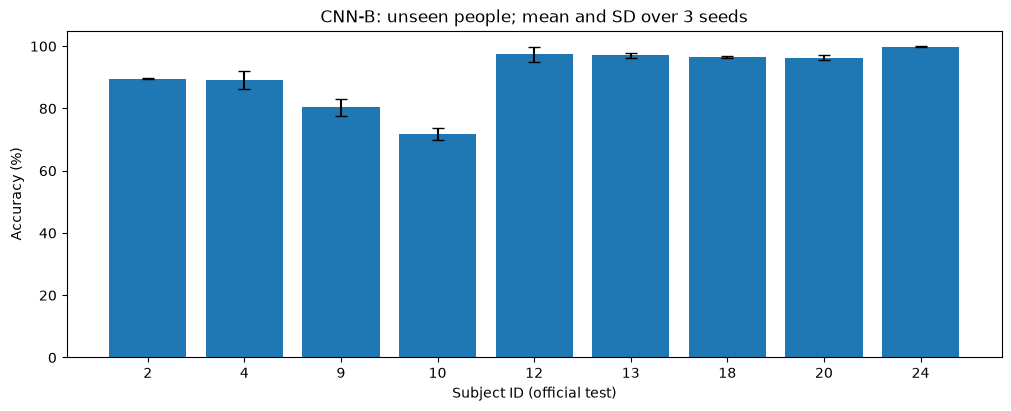

In [6]:
status = json.loads((SOURCE_RESULTS / "test_evaluation_status.json").read_text(encoding="utf-8"))
if status.get("state") != "completed" or status.get("lock_sha256") != sha256_file(SOURCE_RESULTS / "protocol_lock.json"):
    raise ValueError("Kết quả gốc chưa hoàn tất hoặc lock thay đổi")
archived_frames, person_rows, error_rows, archived_input_hashes = {}, [], [], {}
reference_rows = None
for seed in [42, 123, 2026]:
    relative = f"runs/cnn_b_seed{seed}/test_predictions.csv"
    path = SOURCE_RESULTS / relative
    expected = status["result_sha256"].get(relative)
    if expected != sha256_file(path):
        raise ValueError(f"Dự đoán test gốc đã thay đổi: {relative}")
    archived_input_hashes[relative] = expected
    frame = validate_predictions(pd.read_csv(path), "sample_index")
    alignment = frame[["sample_index", "subject_id", "y_true"]].to_numpy()
    if reference_rows is None:
        reference_rows = alignment
    elif not np.array_equal(reference_rows, alignment):
        raise ValueError("Các seed không cùng thứ tự mẫu test")
    archived_frames[seed] = frame
    metrics = calculate_metrics(frame.y_true, frame.y_pred)
    error_rows.append({"seed": seed, **{k: metrics[k] for k in ["accuracy", "macro_f1", "sit_stand_errors", "sitting_to_standing", "standing_to_sitting", "total_errors", "recall_SITTING", "recall_STANDING"]}})
    for person, part in frame.groupby("subject_id"):
        m = calculate_metrics(part.y_true, part.y_pred)
        person_rows.append({"seed": seed, "subject_id": int(person), "samples": len(part), "accuracy": m["accuracy"], "macro_f1": m["macro_f1"]})
person_table = pd.DataFrame(person_rows)
person_summary = person_table.groupby("subject_id").agg(samples=("samples", "first"), accuracy_mean=("accuracy", "mean"), accuracy_std=("accuracy", "std"), macro_f1_mean=("macro_f1", "mean"), macro_f1_std=("macro_f1", "std"))
error_table = pd.DataFrame(error_rows)
display(person_summary)
fig, ax = plt.subplots(figsize=(10, 4), layout="constrained")
ax.bar(person_summary.index.astype(str), person_summary.accuracy_mean*100, yerr=person_summary.accuracy_std*100, capsize=4)
ax.set(xlabel="Subject ID (official test)", ylabel="Accuracy (%)", ylim=(0, 105), title="CNN-B: unseen people; mean and SD over 3 seeds")
archived_subject_figure = fig

## 2. Ngồi và đứng bị nhầm như thế nào?

Confusion matrix dùng CNN-B seed 42 theo quy ước cũ; bảng lỗi dùng đủ ba seed. Hình tín hiệu lấy cửa sổ đầu tiên của SITTING và STANDING ở validation ID 5, không chọn ví dụ theo độ đẹp hoặc kết quả dự đoán. Các hình được lấy từ official train, không phải tín hiệu của mẫu test bị nhầm.

Gia tốc cơ thể đã loại thành phần trọng lực theo tiền xử lý của bộ dữ liệu; gia tốc tổng còn chứa thông tin trọng lực/tư thế. Đây là cơ sở đặt giả thuyết về đầu vào, chưa phải chứng minh nguyên nhân nhầm lẫn.

In [7]:
CHANNELS = [
    "body_acc_x", "body_acc_y", "body_acc_z",
    "body_gyro_x", "body_gyro_y", "body_gyro_z",
    "total_acc_x", "total_acc_y", "total_acc_z",
]
ACTIVITIES = ["WALKING", "WALKING_UPSTAIRS", "WALKING_DOWNSTAIRS", "SITTING", "STANDING", "LAYING"]
train_dir = DATA_DIR / "train"
raw_labels = np.loadtxt(train_dir / "y_train.txt", ndmin=1)
raw_subjects = np.loadtxt(train_dir / "subject_train.txt", ndmin=1)
if raw_labels.ndim != 1 or raw_subjects.shape != raw_labels.shape:
    raise ValueError("Nhãn và subject không cùng số dòng")
if not np.isin(raw_labels, np.arange(1, 7)).all() or not np.isin(raw_subjects, np.arange(1, 31)).all():
    raise ValueError("Nhãn hoặc subject không hợp lệ")
y = raw_labels.astype(np.int64) - 1
subjects = raw_subjects.astype(np.int64)

signal_files = [train_dir / "Inertial Signals" / f"{channel}_train.txt" for channel in CHANNELS]
signals = []
for path in signal_files:
    signal = np.loadtxt(path, dtype=np.float32, ndmin=2)
    if signal.shape != (len(y), 128) or not np.isfinite(signal).all():
        raise ValueError(f"Kích thước hoặc giá trị không hợp lệ: {path.name}")
    signals.append(signal)
X = np.stack(signals, axis=-1)
print("X:", X.shape, X.dtype)
print("y:", y.shape, "labels:", np.unique(y))
print("Subjects:", np.unique(subjects))

X: (7352, 128, 9) float32
y: (7352,) labels: [0 1 2 3 4 5]
Subjects: [ 1  3  5  6  7  8 11 14 15 16 17 19 21 22 23 25 26 27 28 29 30]


In [8]:
if not set(VALIDATION_SUBJECTS).issubset(set(subjects.tolist())):
    raise ValueError("Thiếu người validation trong dữ liệu train")
validation_mask = np.isin(subjects, VALIDATION_SUBJECTS)
fit_indices = np.flatnonzero(~validation_mask)
validation_indices = np.flatnonzero(validation_mask)
x_fit_raw, y_fit = X[fit_indices], y[fit_indices]
x_val_raw, y_val = X[validation_indices], y[validation_indices]
if set(subjects[fit_indices]) & set(subjects[validation_indices]):
    raise ValueError("Trùng người giữa fit-train và validation")
if any(set(labels.tolist()) != set(range(6)) for labels in (y_fit, y_val)):
    raise ValueError("Mỗi tập cần đủ sáu lớp")
print("Fit-train:", x_fit_raw.shape, "Validation:", x_val_raw.shape)
distribution = pd.DataFrame({
    "activity": ACTIVITIES,
    "fit_train": np.bincount(y_fit, minlength=6),
    "validation": np.bincount(y_val, minlength=6),
}).set_index("activity")
display(distribution)

Fit-train: (5982, 128, 9) Validation: (1370, 128, 9)


,fit_train,validation
activity,,
WALKING,1000,226
WALKING_UPSTAIRS,877,196
WALKING_DOWNSTAIRS,804,182
SITTING,1038,248
STANDING,1124,250
LAYING,1139,268


,seed,accuracy,macro_f1,sit_stand_errors,sitting_to_standing,standing_to_sitting,total_errors,recall_SITTING,recall_STANDING
0,42,0.910078,0.910806,197,104,93,265,0.769857,0.825188
1,123,0.917543,0.918174,190,120,70,243,0.739308,0.866541
2,2026,0.918222,0.919264,189,81,108,241,0.792261,0.795113


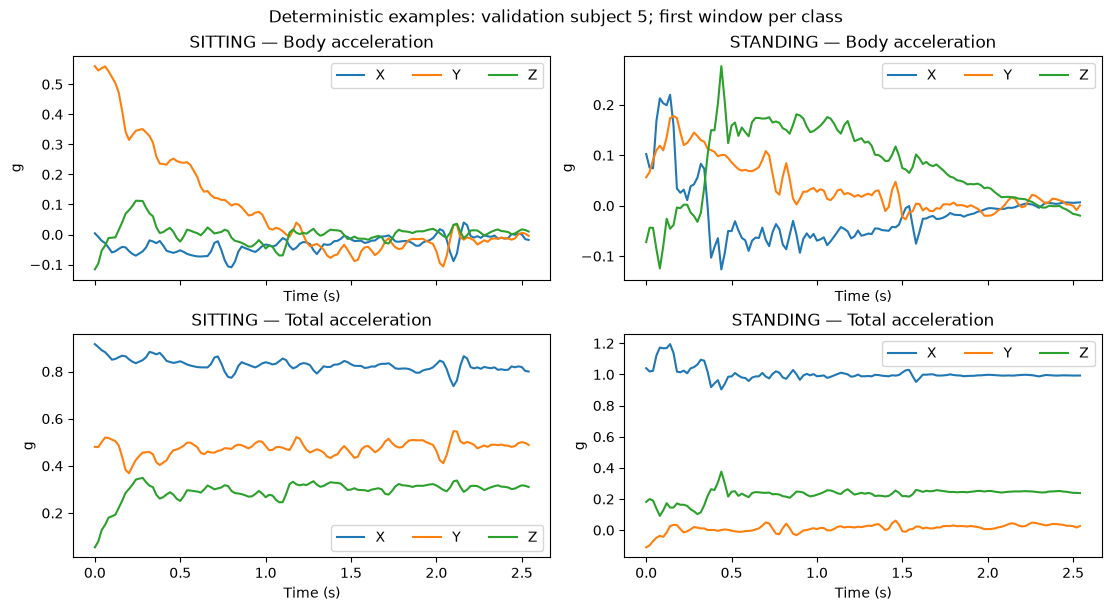

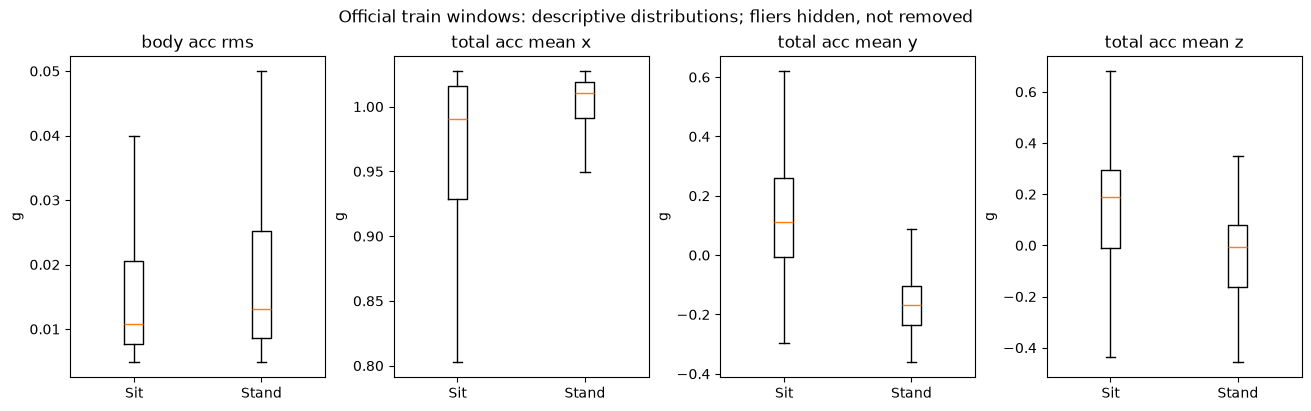

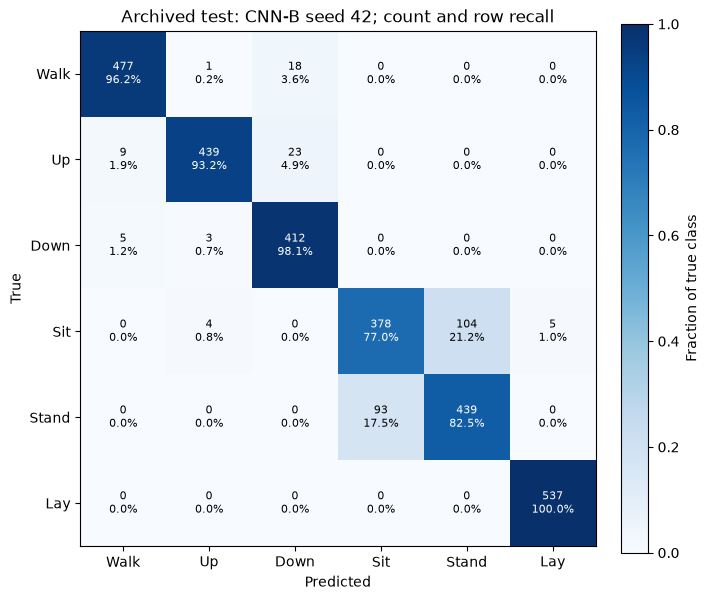

In [9]:
if set(subjects.tolist()) & set(archived_frames[42].subject_id.tolist()):
    raise ValueError("Trùng người official train/test")
example_indices = {label: int(np.flatnonzero((subjects == 5) & (y == label))[0]) for label in [3, 4]}
time_axis = np.arange(128) / 50
fig, axes = plt.subplots(2, 2, figsize=(11, 6), sharex=True, layout="constrained")
for col, label in enumerate([3, 4]):
    idx = example_indices[label]
    for row, (indices, title) in enumerate([([0,1,2], "Body acceleration"), ([6,7,8], "Total acceleration")]):
        for channel, axis_name in zip(indices, "XYZ"):
            axes[row, col].plot(time_axis, X[idx, :, channel], label=axis_name)
        axes[row, col].set(title=f"{ACTIVITIES[label]} — {title}", ylabel="g", xlabel="Time (s)")
        axes[row, col].legend(ncols=3)
fig.suptitle("Deterministic examples: validation subject 5; first window per class")
signal_figure = fig

feature_table = pd.DataFrame({
    "sample_index_in_official_train": np.arange(len(y)), "subject_id": subjects, "activity": [ACTIVITIES[i] for i in y],
    "body_acc_rms": np.sqrt(np.mean(np.sum(X[:,:,:3].astype(float)**2, axis=2), axis=1)),
    **{f"total_acc_mean_{axis}": X[:,:,6+i].mean(axis=1) for i,axis in enumerate("xyz")},
})
static = feature_table[feature_table.activity.isin(["SITTING", "STANDING"])]
fig, axes = plt.subplots(1, 4, figsize=(13, 4), layout="constrained")
for ax, feature in zip(axes, ["body_acc_rms", "total_acc_mean_x", "total_acc_mean_y", "total_acc_mean_z"]):
    ax.boxplot([static.loc[static.activity == name, feature] for name in ["SITTING", "STANDING"]], tick_labels=["Sit", "Stand"], showfliers=False)
    ax.set(title=feature.replace("_", " "), ylabel="g")
fig.suptitle("Official train windows: descriptive distributions; fliers hidden, not removed")
feature_figure = fig
display(error_table)
cm = np.asarray(calculate_metrics(archived_frames[42].y_true, archived_frames[42].y_pred)["confusion_matrix"])
fig, ax = plt.subplots(figsize=(7, 6), layout="constrained")
im = ax.imshow(cm / cm.sum(axis=1, keepdims=True), vmin=0, vmax=1, cmap="Blues")
for i in range(6):
    for j in range(6):
        ax.text(j, i, f"{cm[i,j]}\n{cm[i,j]/cm[i].sum():.1%}", ha="center", va="center", color="white" if cm[i,j]/cm[i].sum() > .5 else "black", fontsize=8)
ax.set(xticks=range(6), yticks=range(6), xticklabels=["Walk","Up","Down","Sit","Stand","Lay"], yticklabels=["Walk","Up","Down","Sit","Stand","Lay"], xlabel="Predicted", ylabel="True", title="Archived test: CNN-B seed 42; count and row recall")
fig.colorbar(im, ax=ax, label="Fraction of true class")
confusion_figure = fig

## 3. Chỉ gia tốc kế có đủ không? Thêm con quay và gia tốc tổng mang lại gì?

Năm biểu diễn: gia tốc tổng; con quay; gia tốc tổng + con quay; gia tốc cơ thể + con quay; toàn bộ 9 kênh. **Body acceleration và total acceleration không phải hai cảm biến vật lý khác nhau.** Không suy ra mức tiêu thụ pin từ số kênh.

Giữ nguyên CNN-B, split, seed, lịch huấn luyện; chỉ đổi đầu vào. Số tham số lớp đầu thay đổi theo số kênh. Dùng validation cho early stopping nên kết quả phần này là đánh giá phát triển trên một split, không phải test độc lập. So sánh đủ seed và ghi nhận cả kết quả không cải thiện.

In [10]:
def build_sensor_cnn(n_channels):
    layers = tf.keras.layers
    model = tf.keras.Sequential(name="cnn_b_sensor")
    model.add(layers.Input(shape=(128, n_channels)))
    model.add(layers.Conv1D(64, kernel_size=5, padding="same", activation="relu"))
    model.add(layers.MaxPooling1D(pool_size=2))
    model.add(layers.Conv1D(128, kernel_size=3, padding="same", activation="relu"))
    model.add(layers.GlobalAveragePooling1D())
    model.add(layers.Dense(64, activation="relu"))
    model.add(layers.Dropout(DROPOUT))
    model.add(layers.Dense(6, activation="softmax"))
    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=LEARNING_RATE),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"],
    )
    return model

In [11]:
def make_tf_dataset(x, labels, seed, training=False):
    dataset = tf.data.Dataset.from_tensor_slices((x, labels))
    if training:
        dataset = dataset.shuffle(len(labels), seed=seed, reshuffle_each_iteration=True)
    options = tf.data.Options()
    options.deterministic = True
    options.threading.private_threadpool_size = 2
    options.threading.max_intra_op_parallelism = 2
    return dataset.batch(BATCH_SIZE).with_options(options).prefetch(1)


def make_callbacks(folder):
    return [
        tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=PATIENCE, restore_best_weights=True),
        tf.keras.callbacks.ModelCheckpoint(str(folder / "model.keras"), monitor="val_loss", save_best_only=True),
        tf.keras.callbacks.CSVLogger(str(folder / "history.csv")),
        tf.keras.callbacks.TerminateOnNaN(),
    ]

In [12]:
is_smoke_study = RUN_MODE == "smoke" or (RUN_MODE == "inspect" and archived_config.get("kind") == "smoke")
chosen_groups = ["all_9"] if is_smoke_study else list(GROUPS)
chosen_seeds = [42] if is_smoke_study else SEEDS
validate_seeds(chosen_seeds)
run_config = {
    "kind": "smoke" if is_smoke_study else "post_test_exploratory_validation",
    "groups": {name: GROUPS[name] for name in chosen_groups}, "seeds": chosen_seeds,
    "validation_subjects": VALIDATION_SUBJECTS, "learning_rate": LEARNING_RATE,
    "batch_size": BATCH_SIZE, "epochs_max": 1 if is_smoke_study else MAX_EPOCHS,
    "patience": PATIENCE, "dropout": DROPOUT, "new_test_inference": False,
}
source_paths = signal_files + [train_dir / "y_train.txt", train_dir / "subject_train.txt"]
input_hashes = {p.relative_to(DATA_DIR).as_posix(): sha256_file(p) for p in source_paths}
if RUN_MODE == "inspect":
    for key, value in run_config.items():
        if archived_config.get(key) != value:
            raise ValueError(f"Cấu hình không khớp đợt đã lưu: {key}")
    if input_hashes != archived_config["train_input_sha256"] or archived_input_hashes != archived_config["archived_prediction_sha256"]:
        raise ValueError("Dữ liệu đầu vào thay đổi")
    print("Inspect: không gọi fit hoặc ghi hiện vật.")
else:
    reserve_output(STUDY_ROOT, OUTPUT_BASE, SOURCE_RESULTS)
    (STUDY_ROOT / "figures").mkdir()
    snapshot = STUDY_ROOT / "notebook_source.ipynb"
    snapshot.write_bytes((ROOT / "notebooks/03_practical_questions.ipynb").read_bytes())
    protocol = ROOT / "docs/research/practical-questions.md"
    (STUDY_ROOT / "protocol.md").write_bytes(protocol.read_bytes())
    save_json(STUDY_ROOT / "experiment.json", {
        **run_config, "started_utc": datetime.now(timezone.utc).isoformat(),
        "python": sys.version, "tensorflow": tf.__version__, "numpy": np.__version__,
        "packages": {name: importlib.metadata.version(name) for name in ["tensorflow", "keras", "numpy", "pandas", "scikit-learn", "matplotlib", "nbformat", "nbclient", "ipykernel"]},
        "runtime": {"deterministic_ops_requested": True, "intra_op_threads": tf.config.threading.get_intra_op_parallelism_threads(),
            "inter_op_threads": tf.config.threading.get_inter_op_parallelism_threads(), "dataset_private_threads": 2,
            "dataset_max_intra_op_threads": 2, "TF_ENABLE_ONEDNN_OPTS": os.environ.get("TF_ENABLE_ONEDNN_OPTS")},
        "platform": platform.platform(), "devices": [str(d) for d in tf.config.list_physical_devices()],
        "train_input_sha256": input_hashes, "archived_prediction_sha256": archived_input_hashes,
        "notebook_on_disk_sha256": sha256_file(snapshot), "protocol_sha256": sha256_file(protocol),
        "snapshot_scope": "Saved notebook on disk; actual execution configuration recorded in this file and each config.json",
    })
    save_json(STUDY_ROOT / "split.json", {"fit_indices": fit_indices.tolist(), "validation_indices": validation_indices.tolist(),
        "fit_subjects": np.unique(subjects[fit_indices]).tolist(), "validation_subjects": VALIDATION_SUBJECTS,
        "examples_in_official_train": {ACTIVITIES[k]: v for k,v in example_indices.items()}})
    for group in chosen_groups:
        a, b, mean, std = prepare_channels(x_fit_raw, x_val_raw, group)
        group_root = STUDY_ROOT / "runs" / group
        group_root.mkdir(parents=True)
        np.savez(group_root / "normalization.npz", mean=mean, std=std, channel_indices=GROUPS[group])
        for seed in chosen_seeds:
            folder = group_root / f"seed{seed}"
            folder.mkdir()
            tf.keras.backend.clear_session()
            tf.keras.utils.set_random_seed(seed)
            model = build_sensor_cnn(a.shape[-1])
            save_json(folder / "config.json", {**run_config, "group": group, "seed": seed, "channel_indices": GROUPS[group], "parameters": model.count_params()})
            (folder / "architecture.json").write_text(model.to_json(), encoding="utf-8")
            print(f"Training {group}, seed {seed}", flush=True)
            started = time.perf_counter()
            history = model.fit(
                make_tf_dataset(a, y_fit, seed, training=True),
                validation_data=make_tf_dataset(b, y_val, seed),
                epochs=run_config["epochs_max"], callbacks=make_callbacks(folder), shuffle=False, verbose=0,
            )
            seconds = time.perf_counter() - started
            if not all(np.isfinite(v) for values in history.history.values() for v in values):
                raise ValueError("Lịch sử có giá trị không hữu hạn")
            best = tf.keras.models.load_model(folder / "model.keras")
            probabilities = np.asarray(best.predict(b, batch_size=BATCH_SIZE, verbose=0))
            np.testing.assert_allclose(probabilities[:64], model.predict(b[:64], verbose=0), rtol=1e-5, atol=1e-6)
            frame = pd.DataFrame({"sample_index_in_official_train": validation_indices, "subject_id": subjects[validation_indices], "y_true": y_val, "y_pred": probabilities.argmax(axis=1)})
            for i, name in enumerate(ACTIVITIES): frame["p_"+name] = probabilities[:,i]
            validate_predictions(frame, "sample_index_in_official_train")
            frame.to_csv(folder / "validation_predictions.csv", index=False)
            metrics = {**calculate_metrics(y_val, frame.y_pred), "group": group, "seed": seed,
                "kind": run_config["kind"], "split": "validation", "new_test_inference": False,
                "parameters": model.count_params(), "training_seconds": seconds,
                "epochs_run": len(history.history["loss"]), "best_epoch": int(np.argmin(history.history["val_loss"])+1),
                "checkpoint_reload_verified": True, "checkpoint_sha256": sha256_file(folder / "model.keras")}
            save_json(folder / "validation_metrics.json", metrics)
            print(f"  Macro-F1={metrics['macro_f1']:.4f}, Accuracy={metrics['accuracy']:.4f}, {seconds:.1f}s", flush=True)

Inspect: không gọi fit hoặc ghi hiện vật.


,group,seed,accuracy,macro_f1,sit_stand_errors,sitting_to_standing,standing_to_sitting,total_errors,parameters,training_seconds,epochs_run,best_epoch,recall_WALKING,recall_WALKING_UPSTAIRS,recall_WALKING_DOWNSTAIRS,recall_SITTING,recall_STANDING,recall_LAYING
0,total_acc,42,0.909489,0.911371,53,10,43,124,34374,43.491106,16,8,1.000000,0.795918,1.000000,0.834677,0.828,1.000000
1,total_acc,123,0.937226,0.938784,45,10,35,86,34374,59.323583,20,12,0.942478,0.933673,1.000000,0.899194,0.860,1.000000
2,total_acc,2026,0.897810,0.898406,51,8,43,140,34374,27.473508,12,4,0.823009,0.923469,1.000000,0.830645,0.828,1.000000
3,gyro,42,0.755474,0.768176,35,13,22,335,34374,93.808802,27,19,0.699115,0.948980,0.967033,0.709677,0.756,0.559701
4,gyro,123,0.745985,0.763290,66,9,57,348,34374,99.211106,33,25,0.884956,0.933673,0.928571,0.814516,0.604,0.436567
5,gyro,2026,0.768613,0.777370,63,13,50,317,34374,125.290505,41,33,0.845133,0.948980,0.972527,0.911290,0.712,0.354478
6,total_acc_gyro,42,0.924088,0.926910,51,8,43,104,35334,50.505795,16,8,0.933628,0.959184,1.000000,0.846774,0.828,1.000000
7,total_acc_gyro,123,0.930657,0.932811,52,9,43,95,35334,37.479535,12,4,0.920354,0.964286,1.000000,0.891129,0.828,1.000000
8,total_acc_gyro,2026,0.922628,0.923330,51,8,43,106,35334,51.221378,16,8,0.907080,0.913265,1.000000,0.899194,0.828,1.000000
9,body_acc_gyro,42,0.929927,0.936561,32,11,21,96,35334,139.102621,44,36,1.000000,1.000000,1.000000,0.778226,0.900,0.940299


,n_runs,accuracy_mean,accuracy_std,macro_f1_mean,macro_f1_std,parameters,sit_stand_errors_mean,training_seconds_mean
group,,,,,,,,
total_acc,3,0.914842,0.020246,0.916187,0.020615,34374,49.666667,43.429399
gyro,3,0.756691,0.011363,0.769612,0.007149,34374,54.666667,106.103471
total_acc_gyro,3,0.925791,0.004277,0.927684,0.004788,35334,51.333333,46.402236
body_acc_gyro,3,0.922871,0.006377,0.930556,0.005384,35334,35.333333,134.250937
all_9,3,0.950365,0.006321,0.953502,0.005187,36294,50.333333,42.517743


,baseline,candidate,seed,delta_macro_f1,delta_sit_stand_errors
0,total_acc,total_acc_gyro,42,0.015539,-2
1,total_acc,total_acc_gyro,123,-0.005973,7
2,total_acc,total_acc_gyro,2026,0.024924,0
3,body_acc_gyro,all_9,42,0.013871,19
4,body_acc_gyro,all_9,123,0.030545,11
5,body_acc_gyro,all_9,2026,0.024423,15
6,total_acc_gyro,all_9,42,0.023523,0
7,total_acc_gyro,all_9,123,0.026680,-6
8,total_acc_gyro,all_9,2026,0.027254,3


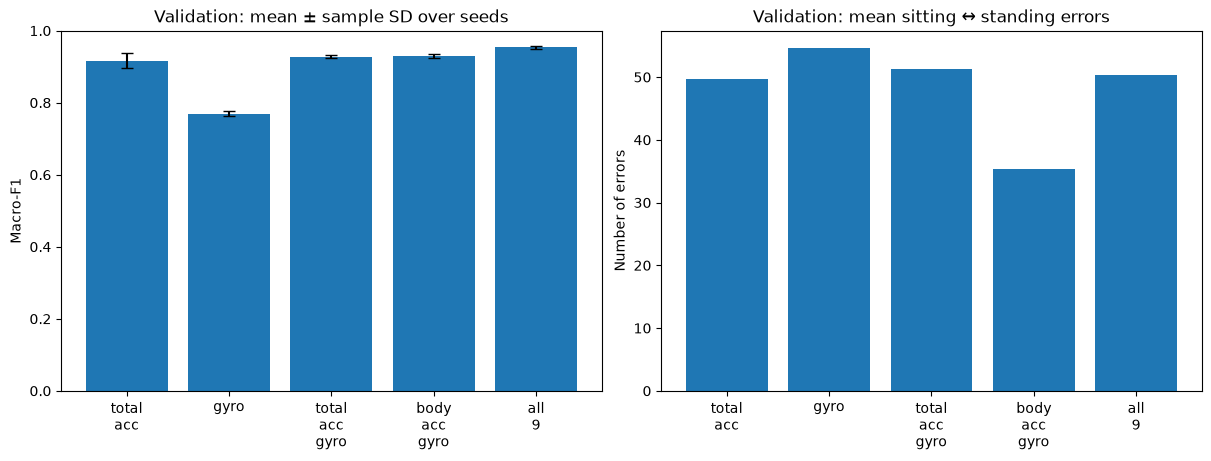

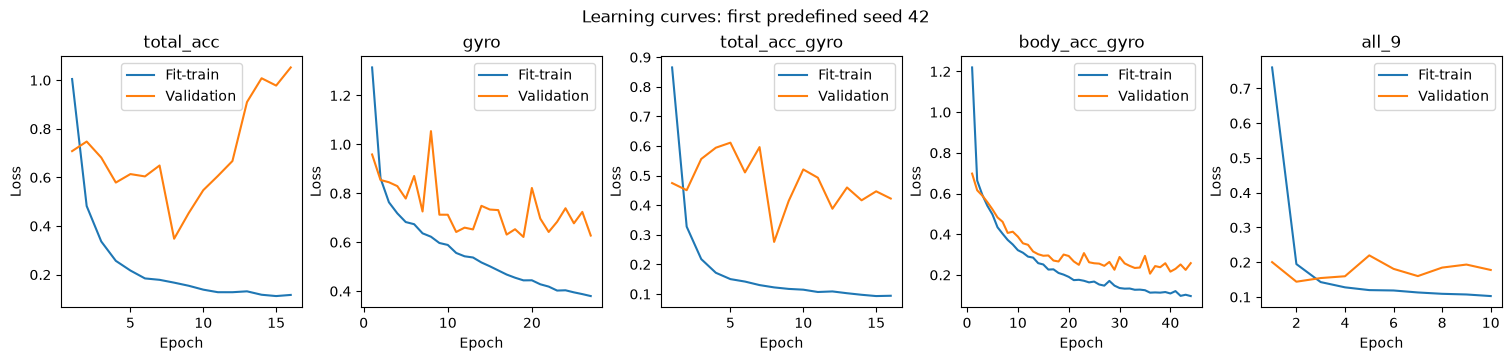

In [13]:
records, person_validation_rows = [], []
for group in chosen_groups:
    for seed in chosen_seeds:
        folder = STUDY_ROOT / "runs" / group / f"seed{seed}"
        stored = json.loads((folder / "validation_metrics.json").read_text(encoding="utf-8"))
        frame = validate_predictions(pd.read_csv(folder / "validation_predictions.csv"), "sample_index_in_official_train")
        if not np.array_equal(frame.sample_index_in_official_train, validation_indices) or not np.array_equal(frame.y_true, y_val) or not np.array_equal(frame.subject_id, subjects[validation_indices]):
            raise ValueError("Dự đoán validation không khớp split")
        recomputed = calculate_metrics(frame.y_true, frame.y_pred)
        for key in ["accuracy", "macro_f1", "sit_stand_errors", "sitting_to_standing", "standing_to_sitting", "total_errors"] + ["recall_"+a for a in ACTIVITIES]:
            if not np.isclose(stored[key], recomputed[key], atol=1e-12, rtol=0):
                raise ValueError(f"Metric không khớp CSV: {group}/{seed}/{key}")
        if stored["confusion_matrix"] != recomputed["confusion_matrix"]:
            raise ValueError("Confusion matrix không khớp")
        records.append({key: stored[key] for key in ["group", "seed", "accuracy", "macro_f1", "sit_stand_errors", "sitting_to_standing", "standing_to_sitting", "total_errors", "parameters", "training_seconds", "epochs_run", "best_epoch"] + ["recall_"+a for a in ACTIVITIES]})
        for person, part in frame.groupby("subject_id"):
            m = calculate_metrics(part.y_true, part.y_pred)
            person_validation_rows.append({"group": group, "seed": seed, "subject_id": int(person), "accuracy": m["accuracy"], "macro_f1": m["macro_f1"]})
run_table = pd.DataFrame(records)
summary = run_table.groupby("group", sort=False).agg(n_runs=("seed", "count"), accuracy_mean=("accuracy", "mean"), accuracy_std=("accuracy", "std"),
    macro_f1_mean=("macro_f1", "mean"), macro_f1_std=("macro_f1", "std"), parameters=("parameters", "first"),
    sit_stand_errors_mean=("sit_stand_errors", "mean"), training_seconds_mean=("training_seconds", "mean"))
display(run_table)
display(summary)
contrasts = [("total_acc", "total_acc_gyro"), ("body_acc_gyro", "all_9"), ("total_acc_gyro", "all_9")]
paired_rows = []
for baseline, candidate in contrasts:
    if baseline not in chosen_groups or candidate not in chosen_groups: continue
    a = run_table[run_table.group == baseline].set_index("seed")
    b = run_table[run_table.group == candidate].set_index("seed")
    for seed in chosen_seeds:
        paired_rows.append({"baseline": baseline, "candidate": candidate, "seed": seed,
            "delta_macro_f1": b.loc[seed,"macro_f1"] - a.loc[seed,"macro_f1"],
            "delta_sit_stand_errors": int(b.loc[seed,"sit_stand_errors"] - a.loc[seed,"sit_stand_errors"])})
paired = pd.DataFrame(paired_rows, columns=["baseline", "candidate", "seed", "delta_macro_f1", "delta_sit_stand_errors"])
display(paired)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), layout="constrained")
labels = [g.replace("_", "\n") for g in summary.index]
axes[0].bar(labels, summary.macro_f1_mean, yerr=summary.macro_f1_std.fillna(0), capsize=4)
axes[0].set(ylabel="Macro-F1", ylim=(0, 1), title="Validation: mean ± sample SD over seeds")
axes[1].bar(labels, summary.sit_stand_errors_mean)
axes[1].set(ylabel="Number of errors", title="Validation: mean sitting ↔ standing errors")
sensor_figure = fig
fig, axes = plt.subplots(1, len(chosen_groups), figsize=(max(5, 3*len(chosen_groups)), 3.5), squeeze=False, layout="constrained")
for ax, group in zip(axes[0], chosen_groups):
    h = pd.read_csv(STUDY_ROOT / "runs" / group / f"seed{chosen_seeds[0]}" / "history.csv")
    ax.plot(h.epoch+1, h.loss, label="Fit-train")
    ax.plot(h.epoch+1, h.val_loss, label="Validation")
    ax.set(title=group, xlabel="Epoch", ylabel="Loss")
    ax.legend()
fig.suptitle(f"Learning curves: first predefined seed {chosen_seeds[0]}")
curves_figure = fig

## 4. Câu trả lời dùng khi thuyết trình

Các đoạn dưới được tạo từ bảng dự đoán đã lưu, không điền trước kết luận. Mean/SD qua ba seed không phải kiểm định ý nghĩa thống kê. Hình tín hiệu chỉ mô tả mẫu và phân phối; kết quả các kênh là kiểm tra giả thuyết bổ sung trên validation.

In [14]:
from IPython.display import Markdown
overall_acc = error_table.accuracy.mean()*100
low, high = person_summary.accuracy_mean.min()*100, person_summary.accuracy_mean.max()*100
fractions = error_table.sit_stand_errors / error_table.total_errors
lines = [
    "# Câu trả lời thực tế từ thực nghiệm HAR", "",
    "Nghiên cứu khám phá bổ sung sau khi đã xem test của protocol 1.0. Test cũ chỉ được đọc từ dự đoán lưu sẵn; thí nghiệm cảm biến mới chỉ đánh giá validation.", "",
    "## 1. Người mới có được nhận dạng tốt không?", "",
    f"CNN-B đạt Accuracy test trung bình {overall_acc:.2f}% qua ba seed trên cùng 9 người chưa xuất hiện trong huấn luyện. Accuracy trung bình theo từng người nằm trong khoảng {low:.2f}%–{high:.2f}%.", "",
    "**Cách giải thích:** mô hình có khả năng nhận dạng người mới trong bộ dữ liệu này, nhưng chất lượng không đồng đều. Điểm trung bình không bảo đảm mọi người đều đạt mức đó. Chưa có bằng chứng về điện thoại, vị trí đeo hoặc bối cảnh khác.", "",
    "## 2. Ngồi và đứng bị nhầm như thế nào?", "",
    f"Số lỗi ngồi–đứng hai chiều qua ba seed là {error_table.sit_stand_errors.tolist()}; chiếm {fractions.min():.1%}–{fractions.max():.1%} tổng lỗi của từng seed.", "",
    "**Cách giải thích:** đây là khó khăn nổi bật quan sát được. Khi ít chuyển động, gia tốc cơ thể có thể cung cấp ít dấu hiệu phân biệt; gia tốc tổng có thể bổ sung thông tin tư thế. Đây là giả thuyết cơ chế, không phải nguyên nhân đã được chứng minh. Hình ví dụ lấy từ validation, không phải cửa sổ test bị nhầm.", "",
    "## 3. Chỉ gia tốc kế có đủ không?", "",
    "Các điểm sau dùng cùng một validation gồm bốn người, cũng được dùng cho early stopping. Chúng chưa phải bằng chứng test độc lập:", "",
    "| Biểu diễn | Accuracy mean ± SD | Macro-F1 mean ± SD | Lỗi ngồi–đứng TB | Tham số |", "|---|---|---|---|---|",
]
for group, row in summary.iterrows():
    sd_acc = f"{row.accuracy_std*100:.2f}" if np.isfinite(row.accuracy_std) else "N/A"
    sd_f1 = f"{row.macro_f1_std:.4f}" if np.isfinite(row.macro_f1_std) else "N/A"
    lines.append(f"| {group} | {row.accuracy_mean*100:.2f}% ± {sd_acc} điểm % | {row.macro_f1_mean:.4f} ± {sd_f1} | {row.sit_stand_errors_mean:.1f} | {int(row.parameters):,} |")
lines += ["", "**So sánh ghép cùng seed:** giá trị dương của ΔMacro-F1 có lợi cho cấu hình bổ sung; giá trị âm của Δlỗi ngồi–đứng nghĩa là ít nhầm hơn.", ""]
for (baseline, candidate), part in paired.groupby(["baseline", "candidate"], sort=False):
    deltas = part.delta_macro_f1
    direction = "nhất quán tăng ở tất cả seed" if (deltas > 0).all() else "nhất quán giảm ở tất cả seed" if (deltas < 0).all() else "khác nhau theo seed hoặc có seed không đổi"
    lines.append(f"- {baseline} → {candidate}: ΔMacro-F1 trung bình {deltas.mean():+.4f}; khoảng qua seed [{deltas.min():+.4f}, {deltas.max():+.4f}], {direction}; Δlỗi ngồi–đứng trung bình {part.delta_sit_stand_errors.mean():+.1f}.")
lines += ["", "**Giới hạn:** số kênh cũng thay đổi tham số lớp đầu; cùng seed không bảo đảm cùng khởi tạo khi kích thước khác nhau. Không đo pin, không suy ra hiệu quả trên điện thoại thật, không khẳng định cảm biến nào luôn tốt nhất. Tổng gia tốc và gia tốc cơ thể là hai biểu diễn từ cùng cảm biến gia tốc.", "",
    "## Bằng chứng để kiểm tra", "", "- `archived_subject_metrics.csv`, `archived_subject_summary.csv`, `archived_error_metrics.csv`: phân tích test cũ.",
    "- `validation_runs.csv`, `validation_summary.csv`, `paired_sensor_deltas.csv`, `validation_subject_metrics.csv`: thí nghiệm mới.",
    "- `runs/`: cấu hình, history, checkpoint và dự đoán từng lượt; `manifest.json`: SHA-256 toàn bộ hiện vật.",
    "- `figures/`: sáu hình từ dữ liệu và dự đoán; `signal_features_train.csv`: đặc trưng mô tả official train.",
]
answers_text = "\n".join(lines) + "\n"
if run_config["kind"] == "smoke":
    answers_text = "# SMOKE: không dùng làm kết quả nghiên cứu\n\n" + answers_text
display(Markdown(answers_text))
for figure, filename in [(archived_subject_figure,"unseen_people.png"), (signal_figure,"sitting_standing_signals.png"),
    (feature_figure,"static_signal_features.png"), (confusion_figure,"sitting_standing_confusion.png"),
    (sensor_figure,"sensor_comparison.png"), (curves_figure,"learning_curves.png")]:
    save_figure(figure, filename)
if RUN_MODE != "inspect":
    for filename, frame in [
        ("archived_subject_metrics.csv", person_table), ("archived_subject_summary.csv", person_summary.reset_index()),
        ("archived_error_metrics.csv", error_table), ("signal_features_train.csv", feature_table),
        ("validation_runs.csv", run_table), ("validation_summary.csv", summary.reset_index()),
        ("paired_sensor_deltas.csv", paired), ("validation_subject_metrics.csv", pd.DataFrame(person_validation_rows)),
    ]:
        frame.to_csv(STUDY_ROOT / filename, index=False)
    (STUDY_ROOT / "answers.md").write_text(answers_text, encoding="utf-8")
    save_json(STUDY_ROOT / "manifest.json", {"state": "completed", "completed_utc": datetime.now(timezone.utc).isoformat(),
        "kind": run_config["kind"], "new_test_inference": False,
        "sha256": {p.relative_to(STUDY_ROOT).as_posix(): sha256_file(p) for p in sorted(STUDY_ROOT.rglob("*")) if p.is_file()}})
else:
    if answers_text != (STUDY_ROOT / "answers.md").read_text(encoding="utf-8"):
        raise ValueError("Câu trả lời không khớp phép tính từ CSV")
    for filename, frame in [("validation_runs.csv", run_table), ("validation_summary.csv", summary.reset_index()),
        ("paired_sensor_deltas.csv", paired), ("archived_subject_summary.csv", person_summary.reset_index()),
        ("archived_error_metrics.csv", error_table), ("validation_subject_metrics.csv", pd.DataFrame(person_validation_rows))]:
        pd.testing.assert_frame_equal(pd.read_csv(STUDY_ROOT / filename), frame, check_dtype=False, atol=1e-12, rtol=1e-10)
    print("PASS: manifest, dữ liệu nguồn, metrics, bảng tổng hợp và câu trả lời; không ghi lại hiện vật.")

# Câu trả lời thực tế từ thực nghiệm HAR

Nghiên cứu khám phá bổ sung sau khi đã xem test của protocol 1.0. Test cũ chỉ được đọc từ dự đoán lưu sẵn; thí nghiệm cảm biến mới chỉ đánh giá validation.

## 1. Người mới có được nhận dạng tốt không?

CNN-B đạt Accuracy test trung bình 91.53% qua ba seed trên cùng 9 người chưa xuất hiện trong huấn luyện. Accuracy trung bình theo từng người nằm trong khoảng 71.88%–99.91%.

**Cách giải thích:** mô hình có khả năng nhận dạng người mới trong bộ dữ liệu này, nhưng chất lượng không đồng đều. Điểm trung bình không bảo đảm mọi người đều đạt mức đó. Chưa có bằng chứng về điện thoại, vị trí đeo hoặc bối cảnh khác.

## 2. Ngồi và đứng bị nhầm như thế nào?

Số lỗi ngồi–đứng hai chiều qua ba seed là [197, 190, 189]; chiếm 74.3%–78.4% tổng lỗi của từng seed.

**Cách giải thích:** đây là khó khăn nổi bật quan sát được. Khi ít chuyển động, gia tốc cơ thể có thể cung cấp ít dấu hiệu phân biệt; gia tốc tổng có thể bổ sung thông tin tư thế. Đây là giả thuyết cơ chế, không phải nguyên nhân đã được chứng minh. Hình ví dụ lấy từ validation, không phải cửa sổ test bị nhầm.

## 3. Chỉ gia tốc kế có đủ không?

Các điểm sau dùng cùng một validation gồm bốn người, cũng được dùng cho early stopping. Chúng chưa phải bằng chứng test độc lập:

| Biểu diễn | Accuracy mean ± SD | Macro-F1 mean ± SD | Lỗi ngồi–đứng TB | Tham số |
|---|---|---|---|---|
| total_acc | 91.48% ± 2.02 điểm % | 0.9162 ± 0.0206 | 49.7 | 34,374 |
| gyro | 75.67% ± 1.14 điểm % | 0.7696 ± 0.0071 | 54.7 | 34,374 |
| total_acc_gyro | 92.58% ± 0.43 điểm % | 0.9277 ± 0.0048 | 51.3 | 35,334 |
| body_acc_gyro | 92.29% ± 0.64 điểm % | 0.9306 ± 0.0054 | 35.3 | 35,334 |
| all_9 | 95.04% ± 0.63 điểm % | 0.9535 ± 0.0052 | 50.3 | 36,294 |

**So sánh ghép cùng seed:** giá trị dương của ΔMacro-F1 có lợi cho cấu hình bổ sung; giá trị âm của Δlỗi ngồi–đứng nghĩa là ít nhầm hơn.

- total_acc → total_acc_gyro: ΔMacro-F1 trung bình +0.0115; khoảng qua seed [-0.0060, +0.0249], khác nhau theo seed hoặc có seed không đổi; Δlỗi ngồi–đứng trung bình +1.7.
- body_acc_gyro → all_9: ΔMacro-F1 trung bình +0.0229; khoảng qua seed [+0.0139, +0.0305], nhất quán tăng ở tất cả seed; Δlỗi ngồi–đứng trung bình +15.0.
- total_acc_gyro → all_9: ΔMacro-F1 trung bình +0.0258; khoảng qua seed [+0.0235, +0.0273], nhất quán tăng ở tất cả seed; Δlỗi ngồi–đứng trung bình -1.0.

**Giới hạn:** số kênh cũng thay đổi tham số lớp đầu; cùng seed không bảo đảm cùng khởi tạo khi kích thước khác nhau. Không đo pin, không suy ra hiệu quả trên điện thoại thật, không khẳng định cảm biến nào luôn tốt nhất. Tổng gia tốc và gia tốc cơ thể là hai biểu diễn từ cùng cảm biến gia tốc.

## Bằng chứng để kiểm tra

- `archived_subject_metrics.csv`, `archived_subject_summary.csv`, `archived_error_metrics.csv`: phân tích test cũ.
- `validation_runs.csv`, `validation_summary.csv`, `paired_sensor_deltas.csv`, `validation_subject_metrics.csv`: thí nghiệm mới.
- `runs/`: cấu hình, history, checkpoint và dự đoán từng lượt; `manifest.json`: SHA-256 toàn bộ hiện vật.
- `figures/`: sáu hình từ dữ liệu và dự đoán; `signal_features_train.csv`: đặc trưng mô tả official train.


PASS: manifest, dữ liệu nguồn, metrics, bảng tổng hợp và câu trả lời; không ghi lại hiện vật.


## Giới hạn và cách dùng kết quả

- Người mới: bằng chứng trên 9 người test của UCI HAR, cùng thiết bị/bối cảnh thu thập; chưa bảo đảm cho mọi người dùng.
- Ngồi–đứng: đã đếm được lỗi; chưa chứng minh nguyên nhân từ một hình mẫu hay từ ID người.
- Cảm biến: so sánh biểu diễn đầu vào trên một validation theo người; còn cần đánh giá độc lập nếu muốn xác nhận ưu thế.
- Không dùng những điểm này để điều chỉnh tiếp rồi báo cáo cùng test như dữ liệu chưa từng xem.
- Notebook và `answers.md` cung cấp bằng chứng để trình bày; kết quả âm hoặc không nhất quán cũng cần được giữ lại.